Forma del dataset: (284807, 31)
Valores nulos totales: 0

Distribución de clases:
 Class
0    284315
1       492
Name: count, dtype: int64
Porcentaje de fraude: 0.173%


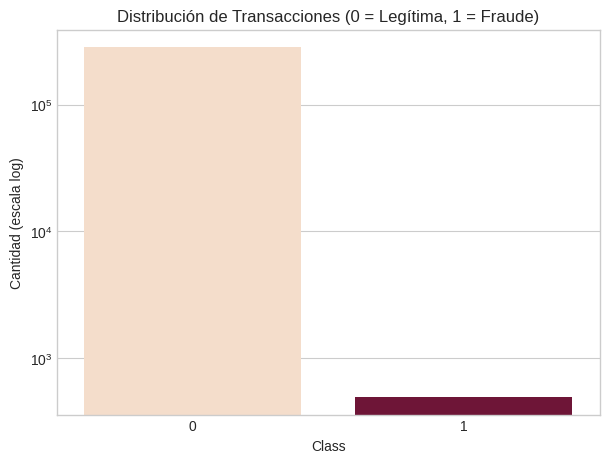

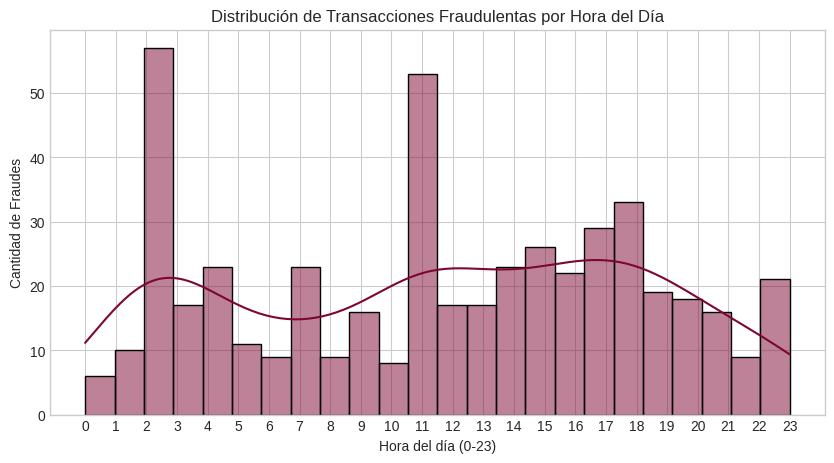

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo
plt.style.use('seaborn-v0_8-whitegrid')

# 1. Carga de datos (ajusta la ruta según la ubicación de tu csv)
# Si el csv está en la raíz y el notebook en 01_notebook, la ruta es '../creditcard.csv'
df = pd.read_csv('/home/kat/Documentos/programacion_avanzada/bank/archive/creditcard.csv')

# 2. Análisis Exploratorio inicial
print("Forma del dataset:", df.shape)
print("Valores nulos totales:", df.isnull().sum().sum())

# 3. Transformación: Crear franja horaria a partir de 'Time' (segundos desde la primera transacción)
df['Hour'] = (df['Time'] // 3600) % 24

# 4. Distribución de la variable objetivo (Class: 0 = Legítima, 1 = Fraude)
conteo_clases = df['Class'].value_counts()
print("\nDistribución de clases:\n", conteo_clases)
print(f"Porcentaje de fraude: {conteo_clases[1] / len(df) * 100:.3f}%")

# Gráfico 1: Distribución de las clases (Escala logarítmica)
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Class', hue='Class', palette=['#FBDCC4', '#7D0633'], legend=False)
plt.title('Distribución de Transacciones (0 = Legítima, 1 = Fraude)')
plt.ylabel('Cantidad (escala log)')
plt.yscale('log') 
plt.show()

# Gráfico 2: Distribución de fraudes por hora
plt.figure(figsize=(10, 5))
sns.histplot(data=df[df['Class'] == 1], x='Hour', bins=24, color='#7D0633', kde=True)
plt.title('Distribución de Transacciones Fraudulentas por Hora del Día')
plt.xticks(range(0, 24))
plt.xlabel('Hora del día (0-23)')
plt.ylabel('Cantidad de Fraudes')
plt.show()

In [6]:
# ==========================================
# MÓDULO 1: PROBABILIDAD Y TEOREMA DE BAYES
# ==========================================

# 1. P(Fraude) Marginal
p_fraude = len(df[df['Class'] == 1]) / len(df)
p_legitima = 1 - p_fraude
print(f"1. Probabilidad marginal P(Fraude): {p_fraude:.6f} ({p_fraude*100:.3f}%)")

# 2. P(Fraude | Monto Alto)
# Definiremos "monto alto" como transacciones mayores a 100 (ajustable)
umbral_monto = 100
monto_alto = df[df['Amount'] > umbral_monto]
p_fraude_dado_monto = len(monto_alto[monto_alto['Class'] == 1]) / len(monto_alto)
print(f"2. P(Fraude | Monto > {umbral_monto}): {p_fraude_dado_monto:.6f} ({p_fraude_dado_monto*100:.3f}%)")

# 3. P(Fraude | Franja Horaria)
# En tu gráfica vimos un pico importante de fraudes alrededor de la hora 2 de la madrugada
hora_pico = 2
transacciones_hora = df[df['Hour'] == hora_pico]
p_fraude_dado_hora = len(transacciones_hora[transacciones_hora['Class'] == 1]) / len(transacciones_hora)
print(f"3. P(Fraude | Hora == {hora_pico}): {p_fraude_dado_hora:.6f} ({p_fraude_dado_hora*100:.3f}%)")

# 4. Teorema de Bayes y Paradoja de la Tasa Base
# Supongamos una regla o modelo antifraude con las siguientes métricas:
sensibilidad = 0.85  # P(Alerta | Fraude): Detecta el 85% de los fraudes reales
especificidad = 0.95 # P(No Alerta | Legítima): Clasifica bien el 95% de las legítimas
p_alerta_dado_legitima = 1 - especificidad # 5% de falsos positivos

# Probabilidad Total de generar una alerta P(Alerta)
p_alerta = (sensibilidad * p_fraude) + (p_alerta_dado_legitima * p_legitima)

# Teorema de Bayes: P(Fraude | Alerta)
p_fraude_dado_alerta = (sensibilidad * p_fraude) / p_alerta

print("\n--- APLICACIÓN DEL TEOREMA DE BAYES ---")
print(f"Sensibilidad: {sensibilidad*100}% | Especificidad: {especificidad*100}%")
print(f"4. P(Fraude | Alerta) = {p_fraude_dado_alerta:.4f} ({p_fraude_dado_alerta*100:.2f}%)")

print("\nExplicación de la Paradoja de la Tasa Base:")
print("A pesar de tener un modelo con 95% de especificidad y 85% de sensibilidad, si salta una alerta, ")
print(f"la probabilidad real de que sea un fraude es solo del {p_fraude_dado_alerta*100:.2f}%. Esto ocurre porque ")
print("la tasa base de fraude es extremadamente baja (0.173%). La inmensa mayoría de las transacciones son ")
print("legítimas, por lo que ese pequeño 5% de falsos positivos inunda el sistema de alertas falsas.")

1. Probabilidad marginal P(Fraude): 0.001727 (0.173%)
2. P(Fraude | Monto > 100): 0.002301 (0.230%)
3. P(Fraude | Hora == 2): 0.017127 (1.713%)

--- APLICACIÓN DEL TEOREMA DE BAYES ---
Sensibilidad: 85.0% | Especificidad: 95.0%
4. P(Fraude | Alerta) = 0.0286 (2.86%)

Explicación de la Paradoja de la Tasa Base:
A pesar de tener un modelo con 95% de especificidad y 85% de sensibilidad, si salta una alerta, 
la probabilidad real de que sea un fraude es solo del 2.86%. Esto ocurre porque 
la tasa base de fraude es extremadamente baja (0.173%). La inmensa mayoría de las transacciones son 
legítimas, por lo que ese pequeño 5% de falsos positivos inunda el sistema de alertas falsas.


--- MOMENTOS ESTADÍSTICOS DEL MONTO ('AMOUNT') POR CLASE ---

Legítima (0):
 Media (Esperanza empírica): 88.2910
 Varianza: 62552.5572
 Asimetría (Skewness): 17.0031
 Curtosis: 846.7370

Fraude (1):
 Media (Esperanza empírica): 122.2113
 Varianza: 65886.3105
 Asimetría (Skewness): 3.7545
 Curtosis: 17.7457

--- AJUSTE DE DISTRIBUCIÓN Y PÉRDIDA ESPERADA ---
Distribución ajustada: Log-Normal
Parámetros: shape=2.5543, scale=14.1624
Pérdida esperada teórica (E[X]): 369.7312


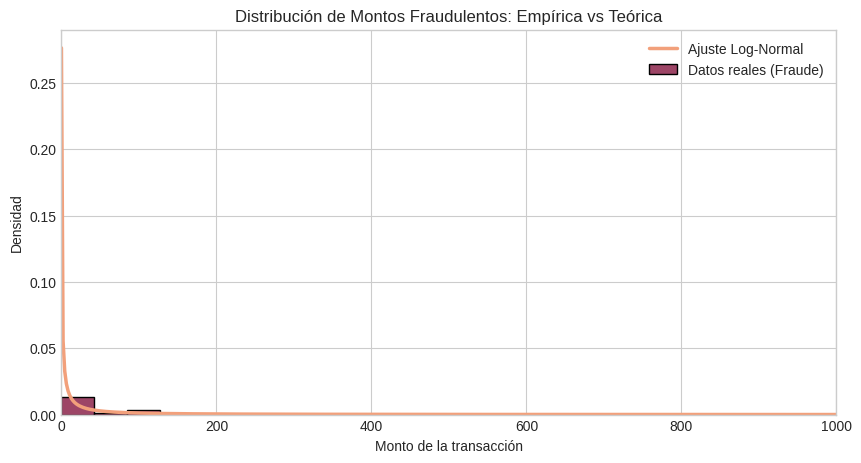

In [7]:
import scipy.stats as stats

# ==========================================
# MÓDULO 2: VARIABLES ALEATORIAS Y MOMENTOS
# ==========================================

print("--- MOMENTOS ESTADÍSTICOS DEL MONTO ('AMOUNT') POR CLASE ---")
for c in [0, 1]:
    clase_nombre = "Legítima (0)" if c == 0 else "Fraude (1)"
    datos_monto = df[df['Class'] == c]['Amount']
    
    print(f"\n{clase_nombre}:")
    print(f" Media (Esperanza empírica): {datos_monto.mean():.4f}")
    print(f" Varianza: {datos_monto.var():.4f}")
    print(f" Asimetría (Skewness): {datos_monto.skew():.4f}")
    print(f" Curtosis: {datos_monto.kurt():.4f}")

# Filtrar los montos de fraude mayores a 0 (el logaritmo de 0 no está definido)
montos_fraude = df[(df['Class'] == 1) & (df['Amount'] > 0)]['Amount']

# Ajuste de distribución Log-Normal
# floc=0 fuerza a que el límite inferior de la distribución sea 0
shape, loc, scale = stats.lognorm.fit(montos_fraude, floc=0)

# La pérdida esperada es la esperanza matemática E[X] del modelo teórico ajustado
perdida_esperada_teorica = stats.lognorm.mean(shape, loc=loc, scale=scale)

print("\n--- AJUSTE DE DISTRIBUCIÓN Y PÉRDIDA ESPERADA ---")
print(f"Distribución ajustada: Log-Normal")
print(f"Parámetros: shape={shape:.4f}, scale={scale:.4f}")
print(f"Pérdida esperada teórica (E[X]): {perdida_esperada_teorica:.4f}")

# Gráfico: Datos reales vs Ajuste Log-Normal
plt.figure(figsize=(10, 5))

# Histograma de densidad de los datos reales (Garnet Red)
sns.histplot(montos_fraude, bins=50, stat='density', color='#7D0633', label='Datos reales (Fraude)')

# Línea de la distribución teórica Log-Normal (Sunset Peach)
x_rango = np.linspace(montos_fraude.min(), montos_fraude.max(), 1000)
pdf_teorica = stats.lognorm.pdf(x_rango, shape, loc=loc, scale=scale)
plt.plot(x_rango, pdf_teorica, color='#F2A07B', linewidth=2.5, label='Ajuste Log-Normal')

plt.title('Distribución de Montos Fraudulentos: Empírica vs Teórica')
plt.xlabel('Monto de la transacción')
plt.ylabel('Densidad')
# Recortamos el eje X a 1000 para visualizar bien la concentración de la curva debido a la asimetría extrema
plt.xlim(0, 1000)
plt.legend()
plt.show()

--- PRUEBA CHI-CUADRADO DE INDEPENDENCIA ---
Estadístico Chi-cuadrado: 674.4434
Valor p: 1.0660e-127
Conclusión: Rechazamos la hipótesis nula. Existe dependencia estadística entre la hora del día y la probabilidad de fraude.

--- MATRICES DE CORRELACIÓN ---


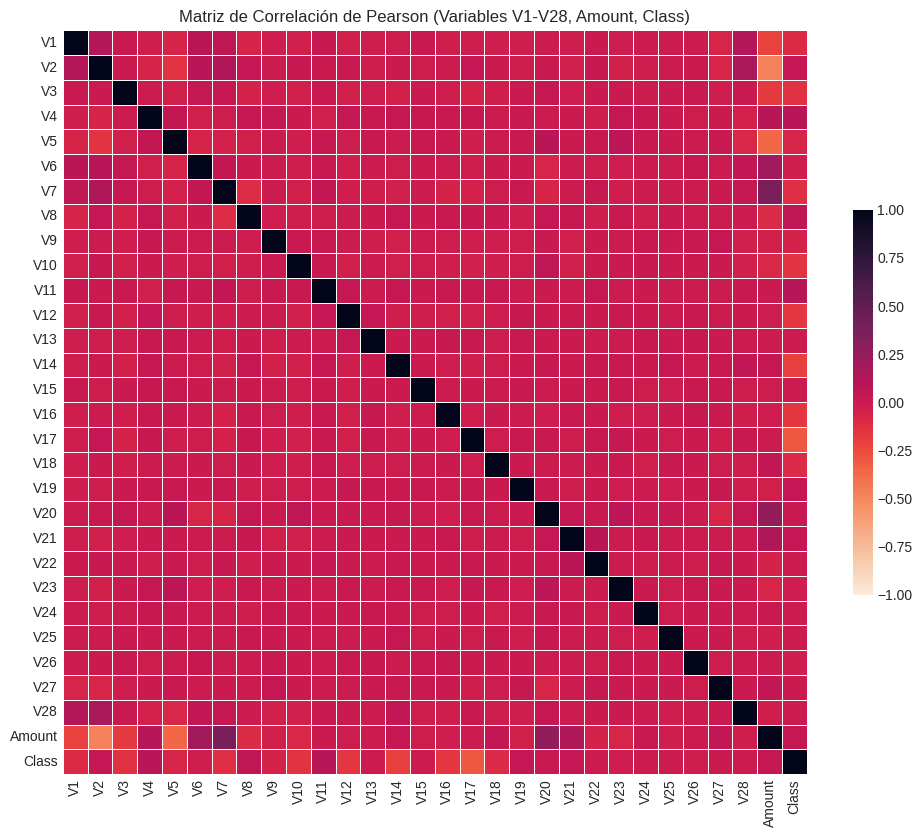


Top 5 variables más correlacionadas con Fraude (Pearson):
V17    0.299371
V14    0.205613
V12    0.160534
V16    0.158727
V10    0.145086
Name: Class, dtype: float64


In [8]:
# ==========================================
# MÓDULO 3: INDEPENDENCIA Y CORRELACIÓN
# ==========================================
from scipy.stats import chi2_contingency

# 1. Prueba Chi-cuadrado: Franja horaria vs Fraude
print("--- PRUEBA CHI-CUADRADO DE INDEPENDENCIA ---")
# Crear tabla de contingencia
tabla_contingencia = pd.crosstab(df['Hour'], df['Class'])
chi2, p_valor, dof, esperados = chi2_contingency(tabla_contingencia)

print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"Valor p: {p_valor:.4e}")
if p_valor < 0.05:
    print("Conclusión: Rechazamos la hipótesis nula. Existe dependencia estadística entre la hora del día y la probabilidad de fraude.")
else:
    print("Conclusión: No podemos rechazar la hipótesis nula. Son independientes.")

# 2. Correlaciones Pearson y Spearman (Muestra aleatoria por rendimiento)
print("\n--- MATRICES DE CORRELACIÓN ---")
# Usamos una muestra porque calcular Spearman en 284k registros es muy pesado
df_muestra = df.sample(n=10000, random_state=42)

# Excluimos 'Time' y 'Hour' para enfocarnos en las V, Amount y Class
columnas_corr = [f'V{i}' for i in range(1, 29)] + ['Amount', 'Class']
df_corr = df_muestra[columnas_corr]

corr_pearson = df_corr.corr(method='pearson')
corr_spearman = df_corr.corr(method='spearman')

# Gráfico de Correlación de Pearson
plt.figure(figsize=(12, 10))
sns.heatmap(corr_pearson, cmap='rocket_r', center=0, vmin=-1, vmax=1, 
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.title('Matriz de Correlación de Pearson (Variables V1-V28, Amount, Class)')
plt.show()

# 3. Extraer las variables más correlacionadas con el fraude (Class)
print("\nTop 5 variables más correlacionadas con Fraude (Pearson):")
correlaciones_clase = corr_pearson['Class'].drop('Class')
print(correlaciones_clase.abs().sort_values(ascending=False).head(5))